# 04.2 Regresión lineal y logística (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: resultados de validación cruzada de este modelo, para compararlos con los demás

Instrucciones:

- Validación: `GroupKFold(n_splits=5, shuffle=True, random_state=SEED)` agrupando por `animal_id_intake`. Es la misma en todos los notebooks.
- Hiperparámetros: salen de la búsqueda con Optuna del mismo modelo (carpeta `04-hyperparameter-optimization-experiment-1`), con `load_best(...)` y los nombres `linear_clf` y `linear_reg`. Si las variables o los datos cambian, hay que repetir esa búsqueda.
- Preprocesamiento: `build_preprocessor(columns=...)` dentro de un `Pipeline`, para que se ajuste en cada fold.
- Métricas: clasificación con macro-F1 y reporte por clase. Regresión con MAE en días (`np.expm1`) y R² en log.
- Resultados por fold: mostrar también el resultado de cada fold, como en `04.1-svm.ipynb` (sección 4).
- No usar `test`.

# Hipótesis del experimento 2
El experimento 1 dejó a este modelo en macro-F1 0,481 y R² 0,222.
Cambio clave: Edad en logaritmo (`age_log`) en regresión para mitigar la cola larga de edades y mejorar R².

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, mean_absolute_error, r2_score

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, NUMERIC_LOG, add_age_log, build_preprocessor
from tuning import load_best

data = add_age_log(pd.read_csv("../../data/processed/dev_features.csv"))
groups = data["animal_id_intake"]
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

c:\Users\MAURO\Desktop\GIT\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs
- `FEATURES_EXP2_CLF` y `FEATURES_EXP2_REG`: variables del experimento 2 para este modelo, en clasificación y en regresión.

In [2]:
FEATURES_EXP2_CLF = CAT_LOW + CAT_HIGH + BINARY + NUMERIC
FEATURES_EXP2_REG = CAT_LOW + CAT_HIGH + BINARY + [c for c in NUMERIC if c != "age_days"] + NUMERIC_LOG
# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

## Hiperparámetros

Salen de la búsqueda con Optuna del experimento 2. Si las variables o los datos cambiaron desde esa búsqueda, `load_best` se detiene y avisa que hay que repetirla.

In [3]:
folder = "../04-hyperparameter-optimization-experiment-2"
params_clf = load_best("linear_clf", FEATURES_EXP2_CLF, folder=folder)
params_reg = load_best("linear_reg", FEATURES_EXP2_REG, folder=folder)

Ajustes cargados de linear_clf.json: {'C': 46.957014810793645, 'class_weight': None}
(en la búsqueda: macro-F1 = 0.4812)
Ajustes cargados de linear_reg.json: {'alpha': 11.193703576923703}
(en la búsqueda: R² (en log) = 0.2191)


## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas.

macro-F1: 0.481



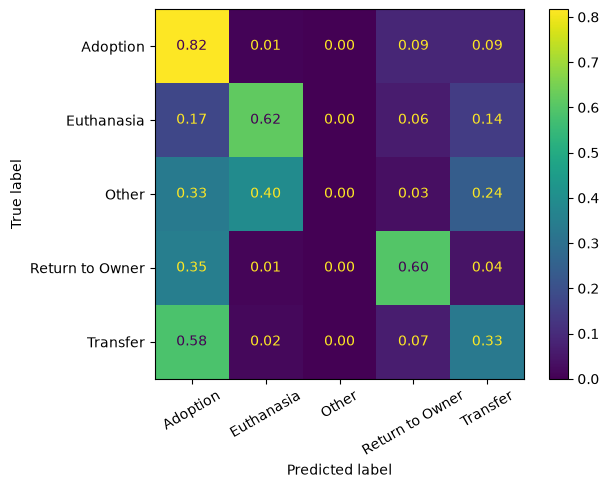

In [4]:
# --- 1. Clasificación ---
# LogisticRegression con max_iter=2000 para evitar UserWarning por límite de iteraciones
pipe_clf = Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF)), 
                     ("model", LogisticRegression(max_iter=2000, **params_clf))])
X_clf = data[FEATURES_EXP2_CLF]

pred_clf = cross_val_predict(pipe_clf, X_clf, y_clf, groups=groups, cv=cv, n_jobs=5)
print(f"macro-F1: {f1_score(y_clf, pred_clf, average='macro'):.3f}\n")
ConfusionMatrixDisplay.from_predictions(y_clf, pred_clf, normalize="true", xticks_rotation=30, values_format=".2f")
plt.show()

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`.

In [5]:
# --- 2. Regresión ---
pipe_reg = Pipeline([("prep", build_preprocessor(numeric=NUMERIC + NUMERIC_LOG, columns=FEATURES_EXP2_REG)), 
                     ("model", Ridge(**params_reg))])
X_reg = data.loc[adopted, FEATURES_EXP2_REG]

pred_log = cross_val_predict(pipe_reg, X_reg, y_reg, groups=groups_reg, cv=cv, n_jobs=5)
days_real = np.expm1(y_reg)

## 3. Resultados

In [8]:
# --- 3. Resultados Globales ---
exp1 = {"Clasificación (macro-F1)": 0.481, "Regresión (R² log)": 0.222, "Regresión (MAE días)": 22.229}
exp2 = {"Clasificación (macro-F1)": f1_score(y_clf, pred_clf, average="macro"),
        "Regresión (R² log)": r2_score(y_reg, pred_log),
        "Regresión (MAE días)": mean_absolute_error(days_real, np.expm1(pred_log))}

pd.DataFrame({"Experimento 1": exp1, "Experimento 2": exp2}).T.round(3)

,Clasificación (macro-F1),Regresión (R² log),Regresión (MAE días)
Experimento 1,0.481,0.222,22.229
Experimento 2,0.481,0.219,22.053


## 4. Resultados por fold

Cada fold deja fuera un grupo distinto de animales para evaluar. Estos son los resultados de cada uno, con los mismos folds en todos los modelos, así que se pueden comparar fold por fold. No vuelve a entrenar nada: usa las predicciones de arriba.

In [7]:
# --- 4. Resultados por fold ---
rows_clf = []
for fold, (_, val) in enumerate(cv.split(X_clf, y_clf, groups), start=1):
    rows_clf.append({"fold": fold, "filas": len(val),
                     "macro-F1": f1_score(y_clf.iloc[val], pred_clf[val], average="macro"),
                     "exactitud": (pred_clf[val] == y_clf.iloc[val]).mean()})

rows_reg = []
for fold, (_, val) in enumerate(cv.split(X_reg, y_reg, groups_reg), start=1):
    rows_reg.append({"fold": fold, "filas": len(val),
                     "R² (log)": r2_score(y_reg.iloc[val], pred_log[val]),
                     "MAE (días)": mean_absolute_error(days_real.iloc[val], np.expm1(pred_log[val]))})

for title, rows in [("Clasificación", rows_clf), ("Regresión", rows_reg)]:
    table = pd.DataFrame(rows).set_index("fold")
    summary = table.drop(columns="filas").agg(["mean", "std"])
    print(f"\n=== {title}: resultado por fold ===")
    print(table.round(3).to_string())
    print(summary.round(3).to_string(), "\n")


=== Clasificación: resultado por fold ===
      filas  macro-F1  exactitud
fold                            
1     12729     0.477      0.605
2     12783     0.481      0.605
3     12697     0.478      0.600
4     12733     0.482      0.606
5     12739     0.488      0.610
      macro-F1  exactitud
mean     0.481      0.605
std      0.004      0.003 


=== Regresión: resultado por fold ===
      filas  R² (log)  MAE (días)
fold                             
1      5393     0.210      22.356
2      5453     0.194      22.233
3      5401     0.245      22.077
4      5405     0.216      21.969
5      5421     0.230      21.631
      R² (log)  MAE (días)
mean     0.219      22.053
std      0.019       0.278 

